# Ejercicio series temporales

In [4]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import kpss, adfuller
from statsmodels.stats.diagnostic import het_arch

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import periodogram
from statsmodels.graphics import tsaplots

El archivo "data.csv" contiene datos de la evolución del número de pasajeros de una aerolínea. Se pide, descomponer ([seasonal_decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html)) la serie temporal. Para ello, debereis decidir que tipo de descomposición requiere  y representar la descomposición para su visualización.

Responde a las siguientes preguntas:
- ¿Qué tipo de descomposición has aplicado? ¿Por qué? 
- ¿Presenta tendencia la serie temporal?En caso afirmativo, ¿cómo es la tendencia?
- Elimina la tendencia de la serie temporal
- ¿Es estacional la serie temporal? En caso afirmatico ¿cuál es el periodo de la componente estacional?
- ¿Es el residuo estrictamente estacionario? Para ello, tendréis que hacer uso de los test estadísticos de Augmented Dickey Fuller ([ADF](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html)) y  Kwiatkowski-Phillips-Schmidt-Shin ([KPSS](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.kpss.html#statsmodels.tsa.stattools.kpss)) que permiten comprobar la estacionariedad en series temporales. También deberéis comprobar que es estacionario en varianza aplicando el [test de heterocedasticidad](https://www.statsmodels.org/dev/generated/statsmodels.stats.diagnostic.het_arch.html).

Para saber el número de puntos que tiene un cierto intervalo temporal, y poder así hacer una mejor definición del periodo de la componente estacional, se puede hacer uso de la librería [pandas.DaraFrame.resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html). 



In [5]:
data = pd.read_csv("TimeSeries_dataset.csv", header=0)
data["date"] = pd.to_datetime(data['date'])
data.set_index("date", inplace=True)
data.head()

,value
date,
2020-01-01,6.000000
2020-01-02,7.392904
2020-01-03,8.078923
2020-01-04,8.017041
2020-01-05,7.297611


<Axes: xlabel='date'>

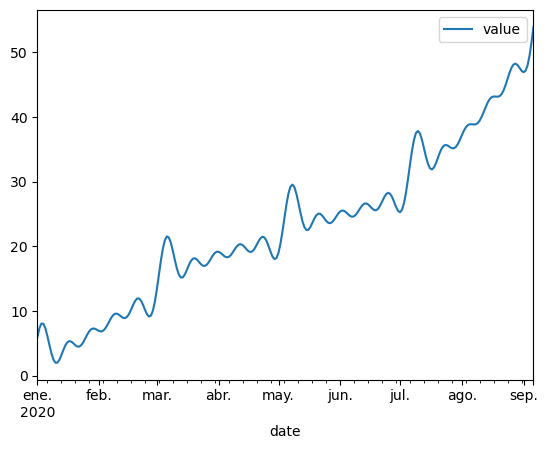

In [6]:
data.plot()

## Seleccion periodo

2020-01-01 -> 2020-09-06 | n = 250
Frecuencia: D
date
2020-01-01    31
2020-02-01    29
2020-03-01    31
2020-04-01    30
2020-05-01    31
2020-06-01    30
2020-07-01    31
2020-08-01    31
2020-09-01     6
Freq: MS, Name: value, dtype: int64
Periodos dominantes (días): [250.0, 125.0, 83.3, 12.5, 15.6, 62.5]


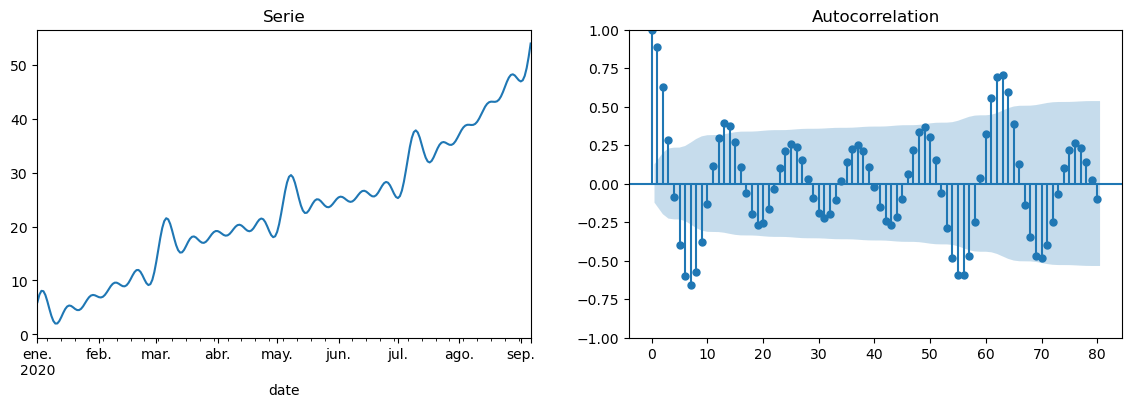

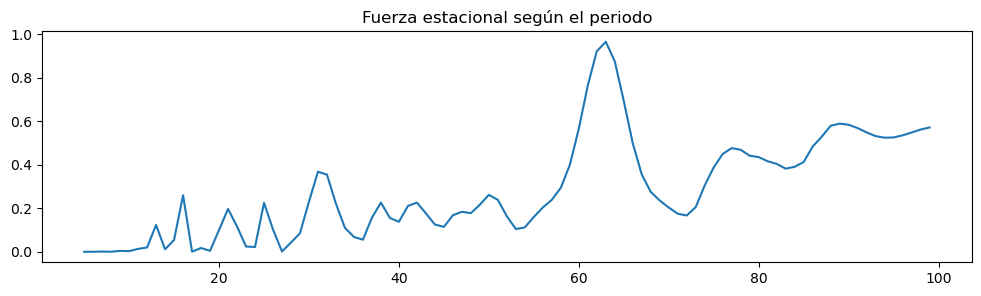

63    0.964703
62    0.921188
64    0.874833
61    0.763960
65    0.693005
dtype: float64


In [7]:
serie = data["value"]

print(serie.index.min().date(), "->", serie.index.max().date(), "| n =", len(serie))
print("Frecuencia:", pd.infer_freq(serie.index))      # D = diaria
print(serie.resample("MS").count())                   # puntos por mes

# Periodograma (sin tendencia lineal)
f, pxx = periodogram(serie.values, detrend="linear")
top = np.argsort(pxx[1:])[::-1][:6] + 1
print("Periodos dominantes (días):", [round(1 / f[i], 1) for i in top])

# Autocorrelación de la serie diferenciada (quita la tendencia y deja ver el ciclo)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
serie.plot(ax=ax[0], title="Serie")
tsaplots.plot_acf(serie.diff().dropna(), lags=80, ax=ax[1])
plt.show()

# Fuerza estacional según el periodo candidato
def fuerza_estacional(serie, periodo, modelo):
    d = seasonal_decompose(serie, model=modelo, period=periodo)
    r = d.resid.dropna()
    s = d.seasonal.loc[r.index]
    if modelo == "additive":
        return max(0, 1 - r.var() / (s + r).var())
    return max(0, 1 - np.log(r).var() / np.log(s * r).var())

cands = range(5, 100)
Fs = pd.Series({p: fuerza_estacional(serie, p, "additive") for p in cands})
Fs.plot(figsize=(12, 3), title="Fuerza estacional según el periodo")
plt.show()
print(Fs.sort_values(ascending=False).head(5))

## Aditiva o multiplicativa

In [8]:
P = 63

for modelo in ["additive", "multiplicative"]:
    d = seasonal_decompose(serie, model=modelo, period=P)
    r = d.resid.dropna()

    # Amplitud estacional de cada ciclo completo
    ciclo = (serie - d.trend) if modelo == "additive" else (serie / d.trend)
    amp = [ciclo.iloc[i:i + P].max() - ciclo.iloc[i:i + P].min()
           for i in range(0, len(serie) - P + 1, P)]

    adf = adfuller(r, autolag="AIC")
    kp = kpss(r, regression="c", nlags="auto")

    print(f"=== {modelo} ===")
    print("Amplitud por ciclo:", np.round(amp, 2))
    print(f"ADF: {adf[0]:.3f} (p={adf[1]:.4f}) | KPSS: {kp[0]:.3f} (p={kp[1]:.4f})")

=== additive ===
Amplitud por ciclo: [ 7.63 10.89 11.4 ]
ADF: 0.127 (p=0.9679) | KPSS: 1.601 (p=0.0100)
=== multiplicative ===
Amplitud por ciclo: [0.57 0.66 0.45]
ADF: -2.830 (p=0.0541) | KPSS: 0.323 (p=0.1000)


C:\Users\maren\AppData\Local\Temp\ipykernel_28484\13853599.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(r, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_28484\13853599.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(r, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_28484\13853599.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whiche

## Descomposicion

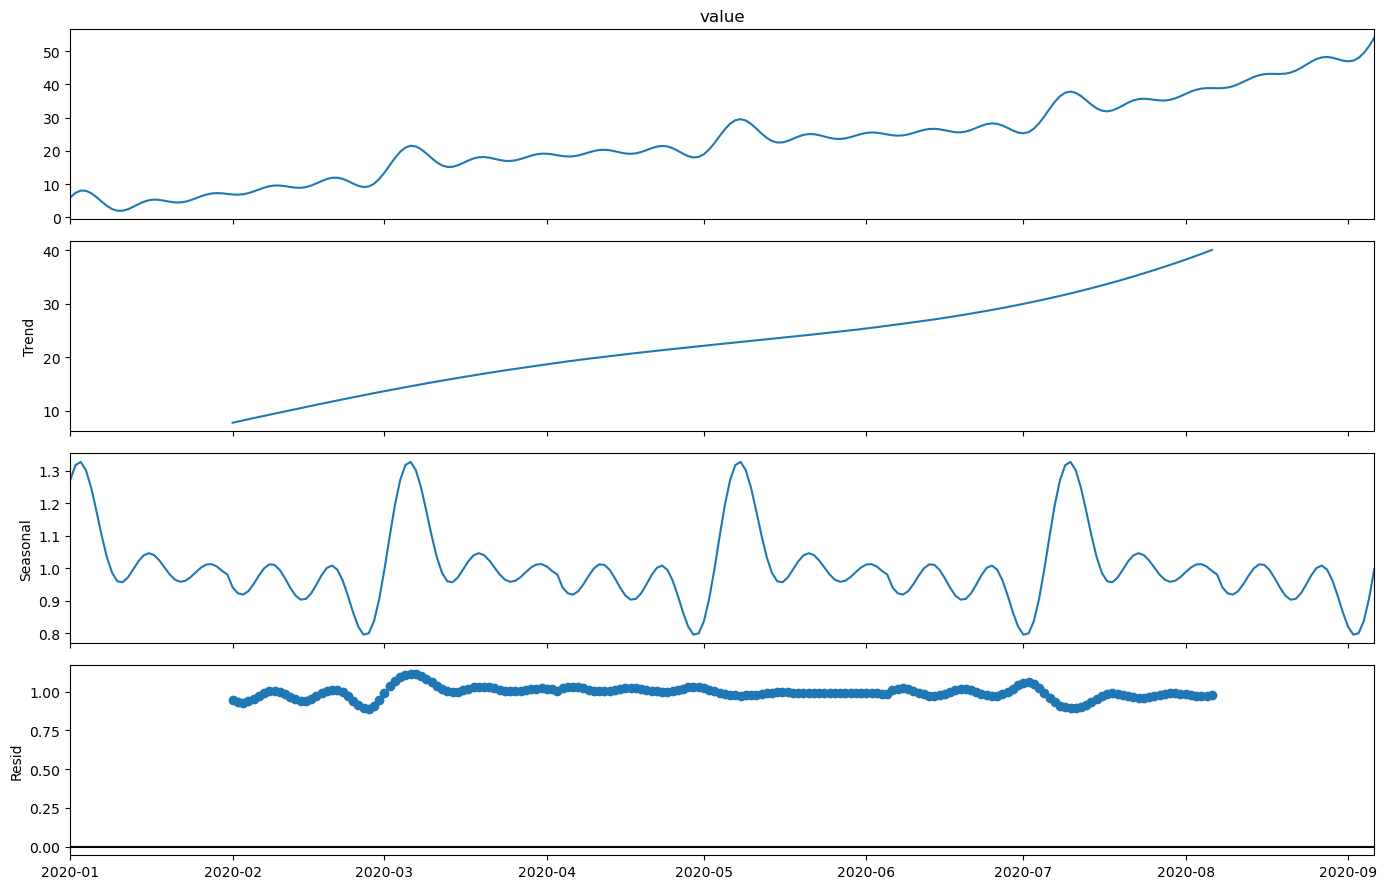

In [9]:
modelo = "multiplicative"
P = 63

dec = seasonal_decompose(serie, model=modelo, period=P)

fig = dec.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

## Eliminar tendencia

Ajuste de grado 1: R2 = 0.9816
Ajuste de grado 2: R2 = 0.9833
Tendencia: 7.7 (2020-02-01) -> 40.1 (2020-08-06)
Pendiente de la serie original: 0.16433017036291156 por día


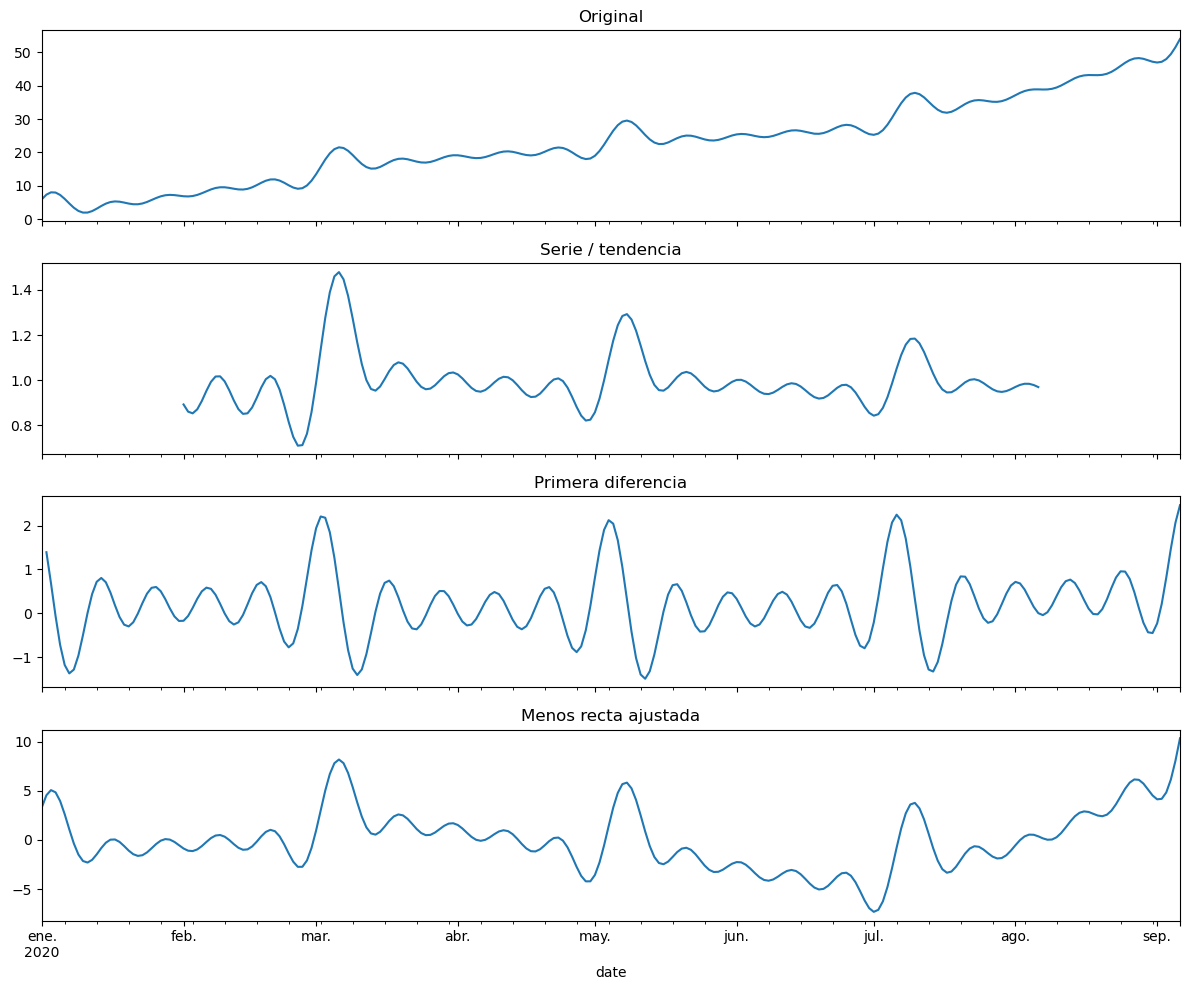

Original         ADF p=0.9988 | KPSS p=0.0100
Serie/tendencia  ADF p=0.0006 | KPSS p=0.1000
Diferencia       ADF p=1.0000 | KPSS p=0.1000
Menos recta      ADF p=0.5106 | KPSS p=0.1000


c:\Users\maren\.conda\envs\data_science_3\Lib\site-packages\statsmodels\tsa\stattools\_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fit()
c:\Users\maren\.conda\envs\data_science_3\Lib\site-packages\statsmodels\tsa\stattools\_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fit()
c:\Users\maren\.conda\envs\data_science_3\Lib\site-packages\statsmodels\tsa\stattools\_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fit()
c:\Users\maren\.conda\envs\data_science_3\Lib\site-packages\statsmodels\tsa\stattools\_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fi

In [10]:
trend = dec.trend.dropna()
t = np.arange(len(trend))

for grado in (1, 2):
    c = np.polyfit(t, trend.values, grado)
    r2 = 1 - ((trend.values - np.polyval(c, t)) ** 2).sum() / ((trend.values - trend.mean()) ** 2).sum()
    print(f"Ajuste de grado {grado}: R2 = {r2:.4f}")

print(f"Tendencia: {trend.iloc[0]:.1f} ({trend.index[0].date()}) -> {trend.iloc[-1]:.1f} ({trend.index[-1].date()})")
print("Pendiente de la serie original:", stats.linregress(np.arange(len(serie)), serie.values)[0], "por día")

# --- Eliminar la tendencia ---
# a) Coherente con el modelo multiplicativo: dividir entre la tendencia
sin_tend_div = serie / dec.trend
# b) Alternativa: primera diferencia
sin_tend_diff = serie.diff().dropna()
# c) Alternativa: quitar una recta
sin_tend_lin = pd.Series(
    serie.values - np.polyval(np.polyfit(np.arange(len(serie)), serie.values, 1), np.arange(len(serie))),
    index=serie.index,
)

fig, ax = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
serie.plot(ax=ax[0], title="Original")
sin_tend_div.plot(ax=ax[1], title="Serie / tendencia")
sin_tend_diff.plot(ax=ax[2], title="Primera diferencia")
sin_tend_lin.plot(ax=ax[3], title="Menos recta ajustada")
plt.tight_layout()
plt.show()

# ¿Qué quedó estacionario en media?
for nombre, x in [("Original", serie), ("Serie/tendencia", sin_tend_div.dropna()),
                  ("Diferencia", sin_tend_diff), ("Menos recta", sin_tend_lin)]:
    print(f"{nombre:16s} ADF p={adfuller(x, autolag='AIC')[1]:.4f} | "
          f"KPSS p={kpss(x, regression='c', nlags='auto')[1]:.4f}")

## Componente estacional

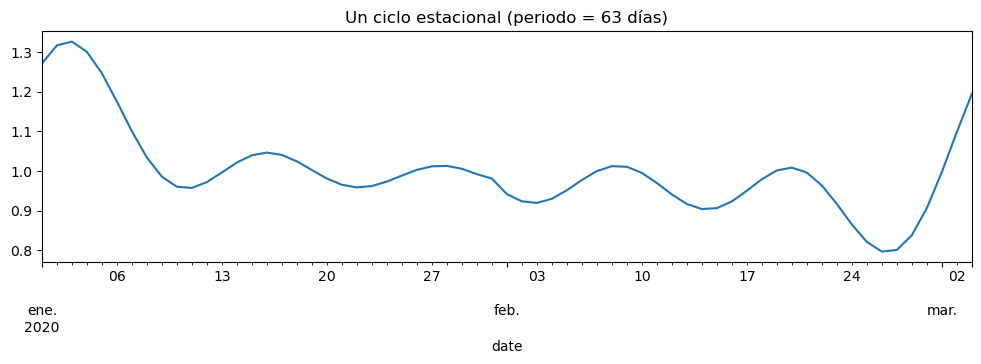

Fuerza estacional: 0.882


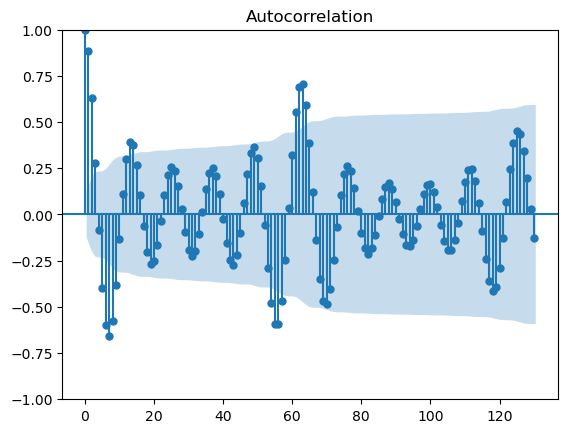

In [11]:
seasonal = dec.seasonal
seasonal.iloc[:P].plot(figsize=(12, 3), title=f"Un ciclo estacional (periodo = {P} días)")
plt.show()

r = dec.resid.dropna()
Fs_final = max(0, 1 - np.log(r).var() / np.log(seasonal.loc[r.index] * r).var())
print(f"Fuerza estacional: {Fs_final:.3f}")

tsaplots.plot_acf(serie.diff().dropna(), lags=130)
plt.show()   # picos cerca de los lags 63 y 126

## Estacionariedad

C:\Users\maren\AppData\Local\Temp\ipykernel_28484\306080617.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(resid, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_28484\306080617.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_stat, kp_p, kp_lags, kp_crit = kpss(resid, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_28484\306080617.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In re

ADF : estadístico=-2.830, p-valor=0.0541, críticos={'1%': -3.466598080268425, '5%': -2.8774669520682674, '10%': -2.5752604356654425}  (H0: raíz unitaria)
KPSS: estadístico=0.323, p-valor=0.1000, críticos={'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}  (H0: estacionaria)
ARCH-LM: LM=176.44, p-valor=1.284e-32  (H0: homocedasticidad)
=> NO estacionario en media (o resultados contradictorios)
=> Heterocedasticidad detectada


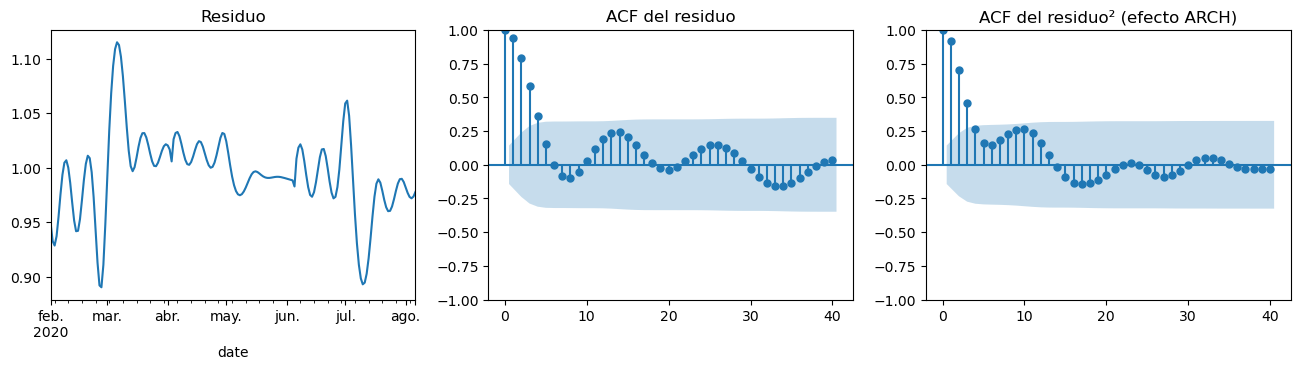

In [12]:
resid = dec.resid.dropna()

adf = adfuller(resid, autolag="AIC")
kp_stat, kp_p, kp_lags, kp_crit = kpss(resid, regression="c", nlags="auto")
lm, lm_p, f_stat, f_p = het_arch((resid - 1) * 100, nlags=10)   # residuo multiplicativo (~1) centrado y en %

print(f"ADF : estadístico={adf[0]:.3f}, p-valor={adf[1]:.4f}, críticos={adf[4]}  (H0: raíz unitaria)")
print(f"KPSS: estadístico={kp_stat:.3f}, p-valor={kp_p:.4f}, críticos={kp_crit}  (H0: estacionaria)")
print(f"ARCH-LM: LM={lm:.2f}, p-valor={lm_p:.4g}  (H0: homocedasticidad)")

if adf[1] < 0.05 and kp_p >= 0.05:
    print("=> Estacionario en media")
else:
    print("=> NO estacionario en media (o resultados contradictorios)")
print("=> Estacionario en varianza" if lm_p >= 0.05 else "=> Heterocedasticidad detectada")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
resid.plot(ax=ax[0], title="Residuo")
tsaplots.plot_acf(resid, lags=40, ax=ax[1], title="ACF del residuo")
tsaplots.plot_acf((resid - 1) ** 2, lags=40, ax=ax[2], title="ACF del residuo² (efecto ARCH)")
plt.show()